# Coarse dates: centuries and millennia

In [1]:
import sys
import tempfile

import duckdb
import matplotlib.pyplot as plt
import numpy as np
import polars as pl

sys.path.insert(0, '../notebooks_analysis')
from style import *

DB_PATH = '../../data/cultura/cultura_enriched_v3.2.duckdb'  # read only
KNOWN_PRECISIONS = ['day', 'month', 'year', 'decade']  # dates precise to the year or the decade
COARSE_PRECISIONS = ['century', 'millennium']
UNIT = {'century': 100, 'millennium': 1000}  # years covered by each coarse precision
AGE_RANGE = (0, 110)  # plausible ages at death, in years
LAST_BIRTH_YEAR = 1920  # born later: may still be alive
CENTURY = 100  # years
MIN_COHORT = 10  # a smaller century takes the median age of everyone
POSITIONS = ['…00', '…01', '…50', 'other round decade', 'other year']
POSITION_COLORS = dict(zip(POSITIONS, [BLUE, ORANGE, GREEN, PURPLE, GREY]))
SHIFT_BINS = np.arange(-150, 151, 10)  # years
TOP_YEARS = 10  # most frequent coarse years that are not round
SEED = 42

pl.Config.set_tbl_rows(30)
pl.Config.set_tbl_cols(-1)
apply_style()

## Data
Birth and death dates from Wikidata only (no estimated date). A birth is **precise** if one of its Wikidata values is precise to the decade or better, **coarse** if its only values are centuries or millennia. A work's date is its inception (P571).

In [2]:
con = duckdb.connect(DB_PATH, read_only=True)
con.sql(f"SET memory_limit='4GB'; SET threads=6; SET temp_directory='{tempfile.mkdtemp()}';")
people = con.sql('''
    WITH wikidata AS (
        SELECT entity.qid AS qid,
               list_filter(birth_date, d -> d.field_provenance['year'].rule IS NULL) AS birth,
               list_filter(death_date, d -> d.field_provenance['year'].rule IS NULL) AS death
        FROM individual
    ),
    inception AS (
        SELECT individual_work.qid,
               bool_or(list_contains($known, work.inception.precision)) AS precise,
               bool_or(list_contains($coarse, work.inception.precision)) AS coarse
        FROM individual_work
        JOIN work ON work.entity.qid = individual_work.work_qid
        GROUP BY individual_work.qid
    ),
    dates AS (
        SELECT wikidata.qid,
               list_filter(wikidata.birth, d -> list_contains($known, d.precision))[1].year AS birth_year,
               list_filter(wikidata.birth, d -> list_contains($coarse, d.precision))[1] AS coarse_birth,
               list_filter(wikidata.death, d -> list_contains($known, d.precision))[1].year AS death_year,
               list_filter(wikidata.death, d -> list_contains($coarse, d.precision))[1] AS coarse_death,
               CASE WHEN inception.qid IS NULL THEN 'no works'
                    WHEN inception.precise THEN 'precise'
                    WHEN inception.coarse THEN 'coarse'
                    ELSE 'no inception' END AS inception
        FROM wikidata
        LEFT JOIN inception ON inception.qid = wikidata.qid
    )
    SELECT qid, birth_year, death_year, inception,
           coarse_birth.year AS coarse_birth_year, coarse_birth.precision AS coarse_birth_precision,
           coarse_death.year AS coarse_death_year, coarse_death.precision AS coarse_death_precision,
           CASE WHEN birth_year IS NOT NULL THEN 'precise' WHEN coarse_birth IS NOT NULL THEN 'coarse' ELSE 'none' END AS birth,
           CASE WHEN death_year IS NOT NULL THEN 'precise' WHEN coarse_death IS NOT NULL THEN 'coarse' ELSE 'none' END AS death
    FROM dates
''', params={'known': KNOWN_PRECISIONS, 'coarse': COARSE_PRECISIONS}).pl()
assert people['qid'].is_unique().all()
print(f'{people.height:,} individuals')
people.filter(pl.col('birth') == 'coarse').sample(5, seed=SEED)

13,002,897 individuals


qid,birth_year,death_year,inception,coarse_birth_year,coarse_birth_precision,coarse_death_year,coarse_death_precision,birth,death
str,i64,i64,str,i64,str,i64,str,str,str
"""Q5956975""",null,null,"""no works""",1250,"""century""",null,null,"""coarse""","""none"""
"""Q21063840""",null,null,"""no works""",1901,"""century""",null,null,"""coarse""","""none"""
"""Q95587394""",null,null,"""no works""",2000,"""century""",null,null,"""coarse""","""none"""
"""Q5620808""",null,null,"""no works""",1801,"""century""",null,null,"""coarse""","""none"""
"""Q6446830""",null,null,"""no works""",1950,"""century""",null,null,"""coarse""","""none"""


In [3]:
coarse_works = con.sql('''
    SELECT DISTINCT work.entity.qid AS work_qid, work.inception.year AS year, work.inception.precision AS precision
    FROM individual_work
    JOIN work ON work.entity.qid = individual_work.work_qid
    WHERE list_contains($coarse, work.inception.precision)
''', params={'coarse': COARSE_PRECISIONS}).pl()
print(f'{coarse_works.height:,} works with a coarse inception')
coarse_works.sample(5, seed=SEED)

103,544 works with a coarse inception


work_qid,year,precision
str,i64,str
"""Q56489088""",1597,"""century"""
"""Q27037956""",1500,"""century"""
"""Q118630435""",1663,"""century"""
"""Q30878653""",1900,"""century"""
"""Q59825038""",1701,"""century"""


## How many individuals have coarse dates

### Birth × death precision

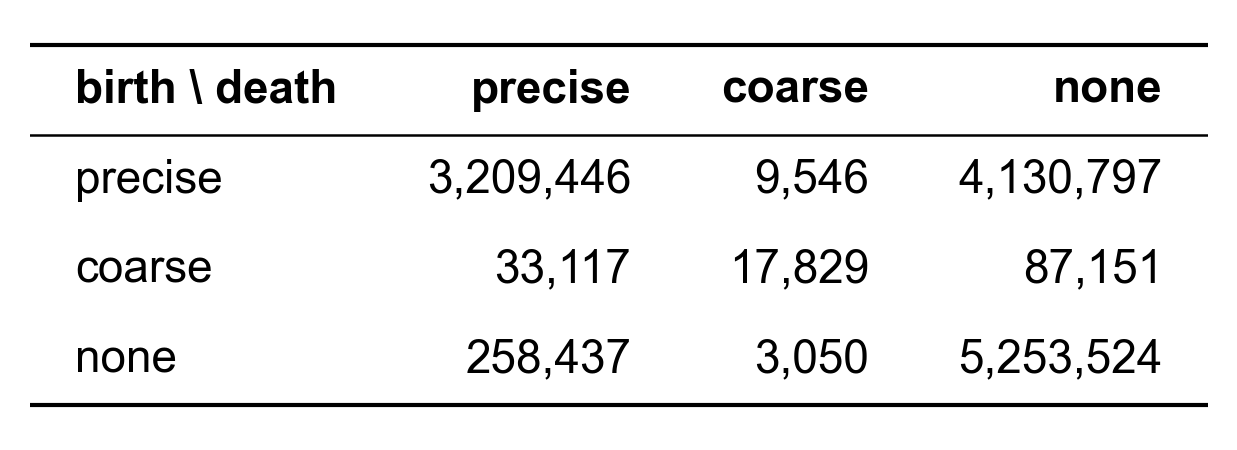

In [4]:
status = (
    people.group_by('birth', 'death').len()
    .pivot(on='death', index='birth', values='len')
    .select('birth', 'precise', 'coarse', 'none')
    .sort(pl.col('birth').replace_strict({'precise': 0, 'coarse': 1, 'none': 2}))
)
assert status.select(pl.sum_horizontal('precise', 'coarse', 'none')).sum().item() == people.height
show_table(status.rename({'birth': 'birth \\ death'}).with_columns(pl.col('precise', 'coarse', 'none').map_elements(lambda n: f'{n:,}', return_dtype=pl.String)))

### Coarse births, coarse deaths and the inception of their works

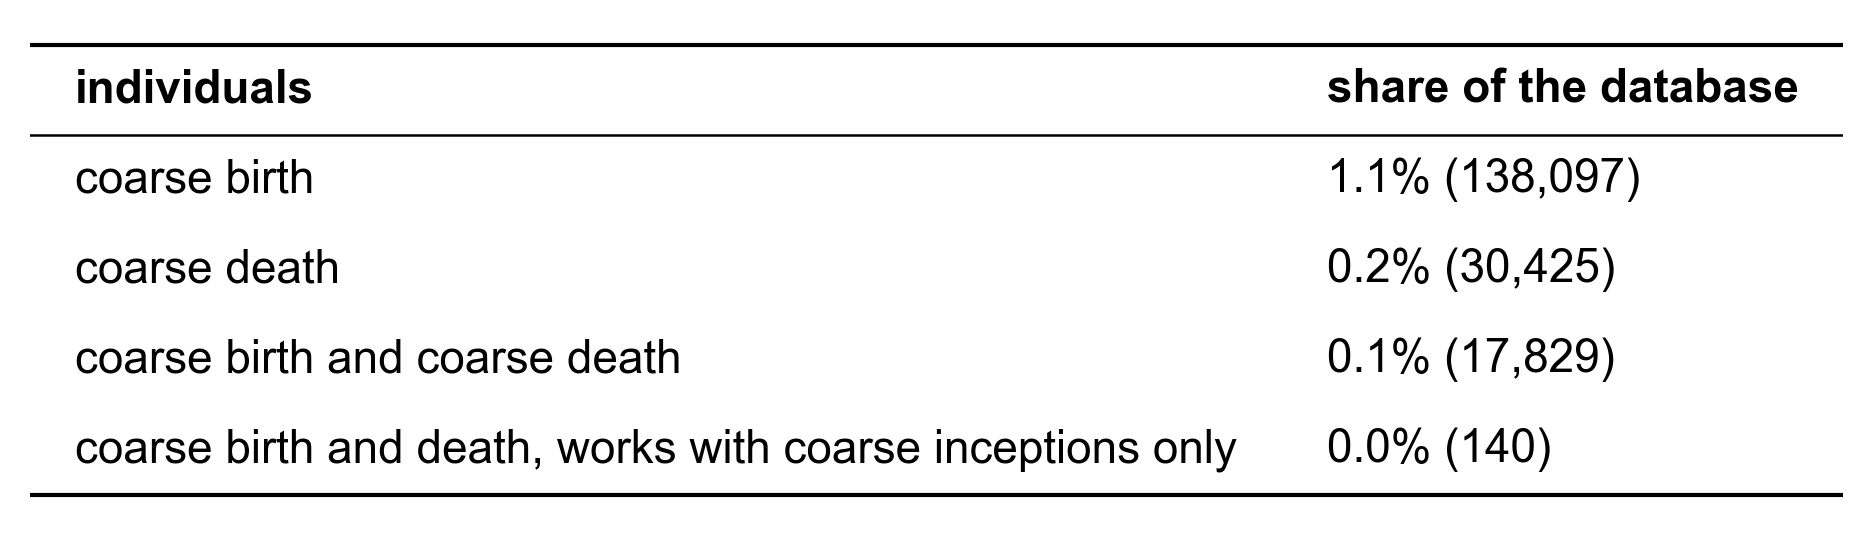

In [5]:
def share(mask, total):
    return f'{100 * mask.sum() / total:.1f}% ({mask.sum():,})'


coarse_birth = people['birth'] == 'coarse'
coarse_death = people['death'] == 'coarse'
both = coarse_birth & coarse_death
summary = pl.DataFrame([
    {'individuals': 'coarse birth', 'share of the database': share(coarse_birth, people.height)},
    {'individuals': 'coarse death', 'share of the database': share(coarse_death, people.height)},
    {'individuals': 'coarse birth and coarse death', 'share of the database': share(both, people.height)},
    {'individuals': 'coarse birth and death, works with coarse inceptions only', 'share of the database': share(both & (people['inception'] == 'coarse'), people.height)},
])
show_table(summary)

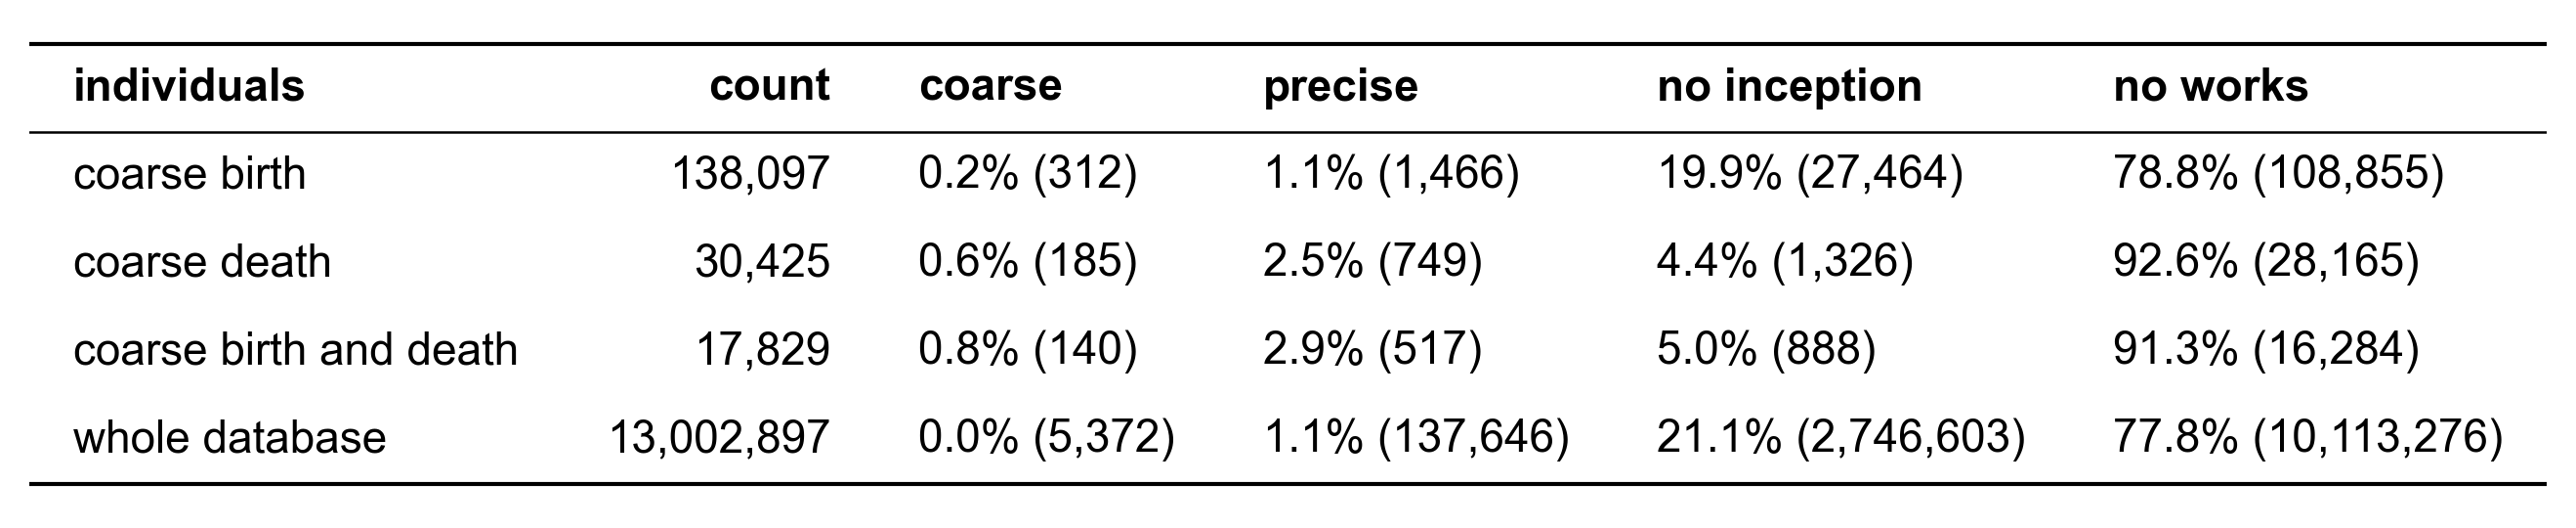

In [6]:
def inception_row(label, mask):
    group = people.filter(mask)
    return {'individuals': label, 'count': f'{group.height:,}'} | {
        status: share(group['inception'] == status, group.height) for status in ['coarse', 'precise', 'no inception', 'no works']
    }


show_table(pl.DataFrame([
    inception_row('coarse birth', coarse_birth),
    inception_row('coarse death', coarse_death),
    inception_row('coarse birth and death', both),
    inception_row('whole database', pl.lit(True)),
]))

## Are coarse dates rounder than they look?
Wikidata stores a coarse date as a year. For a century, that year can be the round year (1600), the first year (1601), the middle (1650) or any other year. A stored year that is not round is more precise than its precision says.

In [7]:
def position(frame, year, precision):
    unit = pl.col(precision).replace_strict(UNIT, return_dtype=pl.Int64)
    rest = pl.col(year).abs() % unit
    return frame.with_columns(
        pl.when(rest == 0).then(pl.lit('…00'))
        .when(rest == 1).then(pl.lit('…01'))
        .when(rest == unit // 2).then(pl.lit('…50'))
        .when(rest % 10 == 0).then(pl.lit('other round decade'))
        .otherwise(pl.lit('other year'))
        .alias('position')
    )


coarse_years = pl.concat([
    position(people.filter(coarse_birth), 'coarse_birth_year', 'coarse_birth_precision').select(pl.lit('birth').alias('date'), pl.col('coarse_birth_year').alias('year'), pl.col('coarse_birth_precision').alias('precision'), 'position'),
    position(people.filter(coarse_death), 'coarse_death_year', 'coarse_death_precision').select(pl.lit('death').alias('date'), pl.col('coarse_death_year').alias('year'), pl.col('coarse_death_precision').alias('precision'), 'position'),
    position(coarse_works, 'year', 'precision').select(pl.lit('work inception').alias('date'), 'year', 'precision', 'position'),
])
assert coarse_years.height == coarse_birth.sum() + coarse_death.sum() + coarse_works.height
coarse_years.sample(5, seed=SEED)

date,year,precision,position
str,i64,str,str
"""work inception""",1545,"""century""","""other year"""
"""birth""",2000,"""century""","""…00"""
"""work inception""",1750,"""century""","""…50"""
"""work inception""",1850,"""century""","""…50"""
"""work inception""",1650,"""century""","""…50"""


### Position of the stored year within its century or millennium

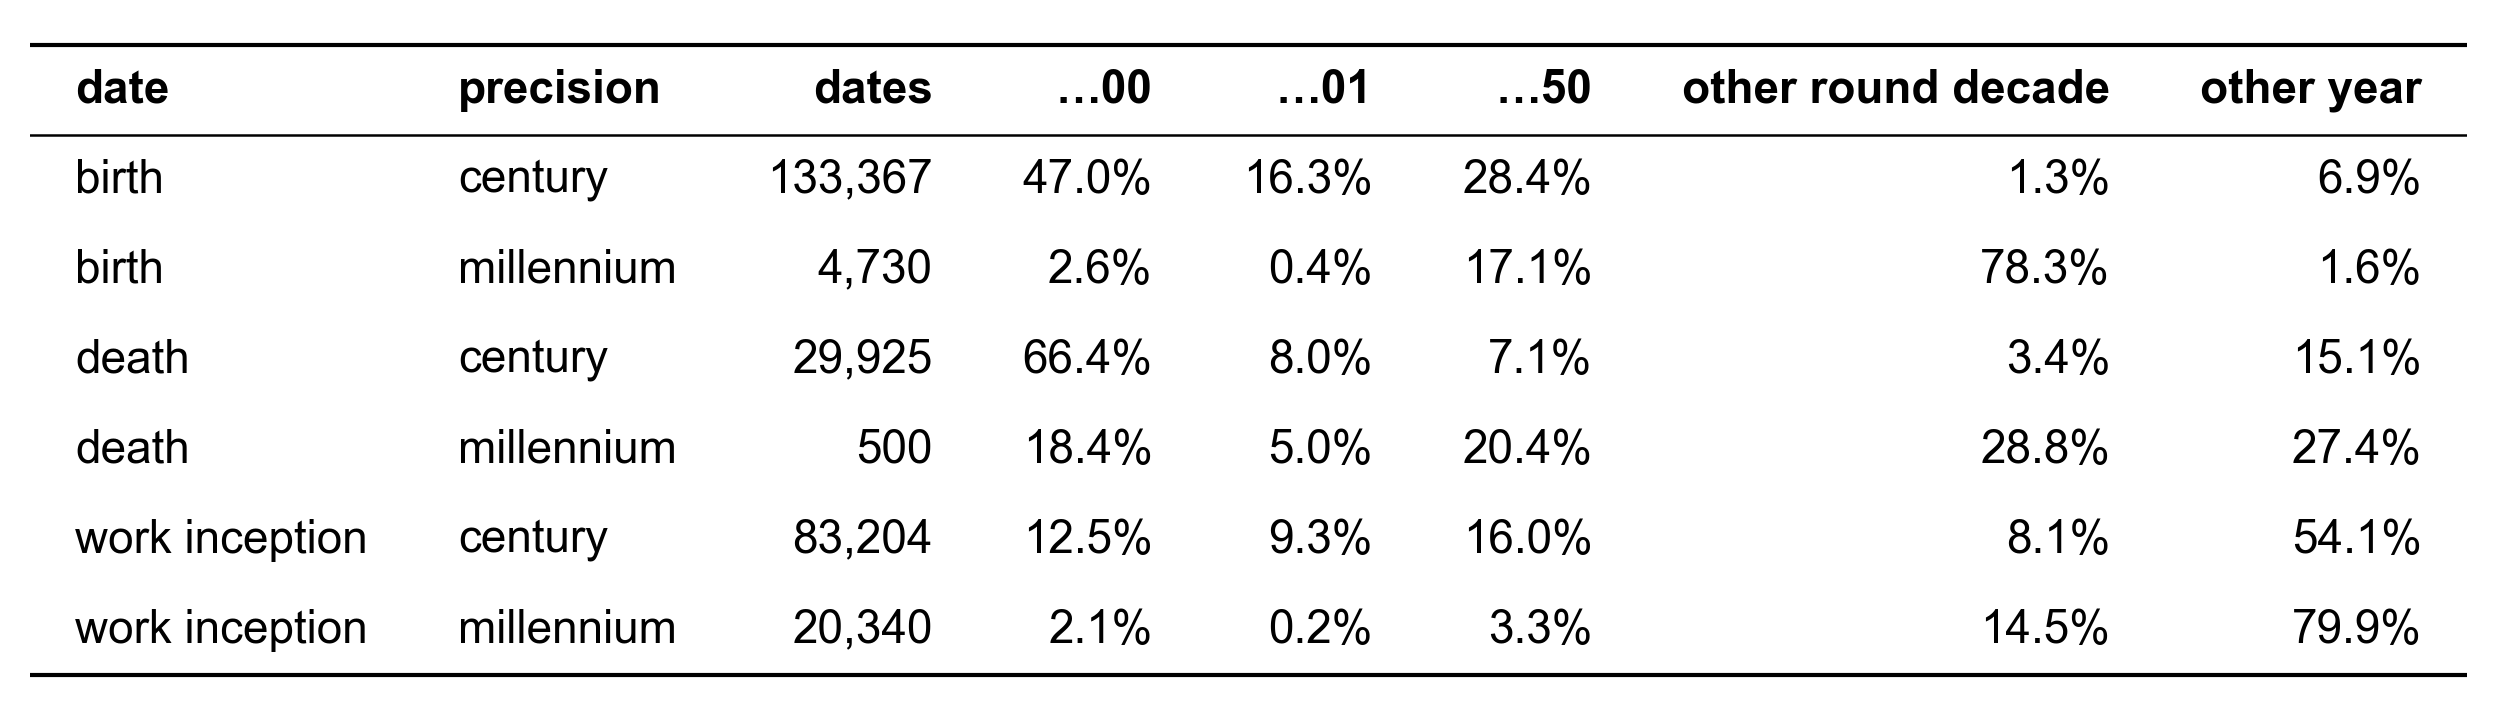

In [8]:
positions = (
    coarse_years.group_by('date', 'precision', 'position').len()
    .with_columns((100 * pl.col('len') / pl.col('len').sum().over('date', 'precision')).alias('share'))
    .pivot(on='position', index=['date', 'precision'], values='share')
    .join(coarse_years.group_by('date', 'precision').len().rename({'len': 'dates'}), on=['date', 'precision'])
    .select('date', 'precision', 'dates', *POSITIONS)
    .fill_null(0)
    .sort('date', 'precision')
)
show_table(positions.with_columns(pl.col('dates').map_elements(lambda n: f'{n:,}', return_dtype=pl.String), pl.col(POSITIONS).map_elements(lambda s: f'{s:.1f}%', return_dtype=pl.String)))

### Figure 1: Year within the century of century-precision births and deaths

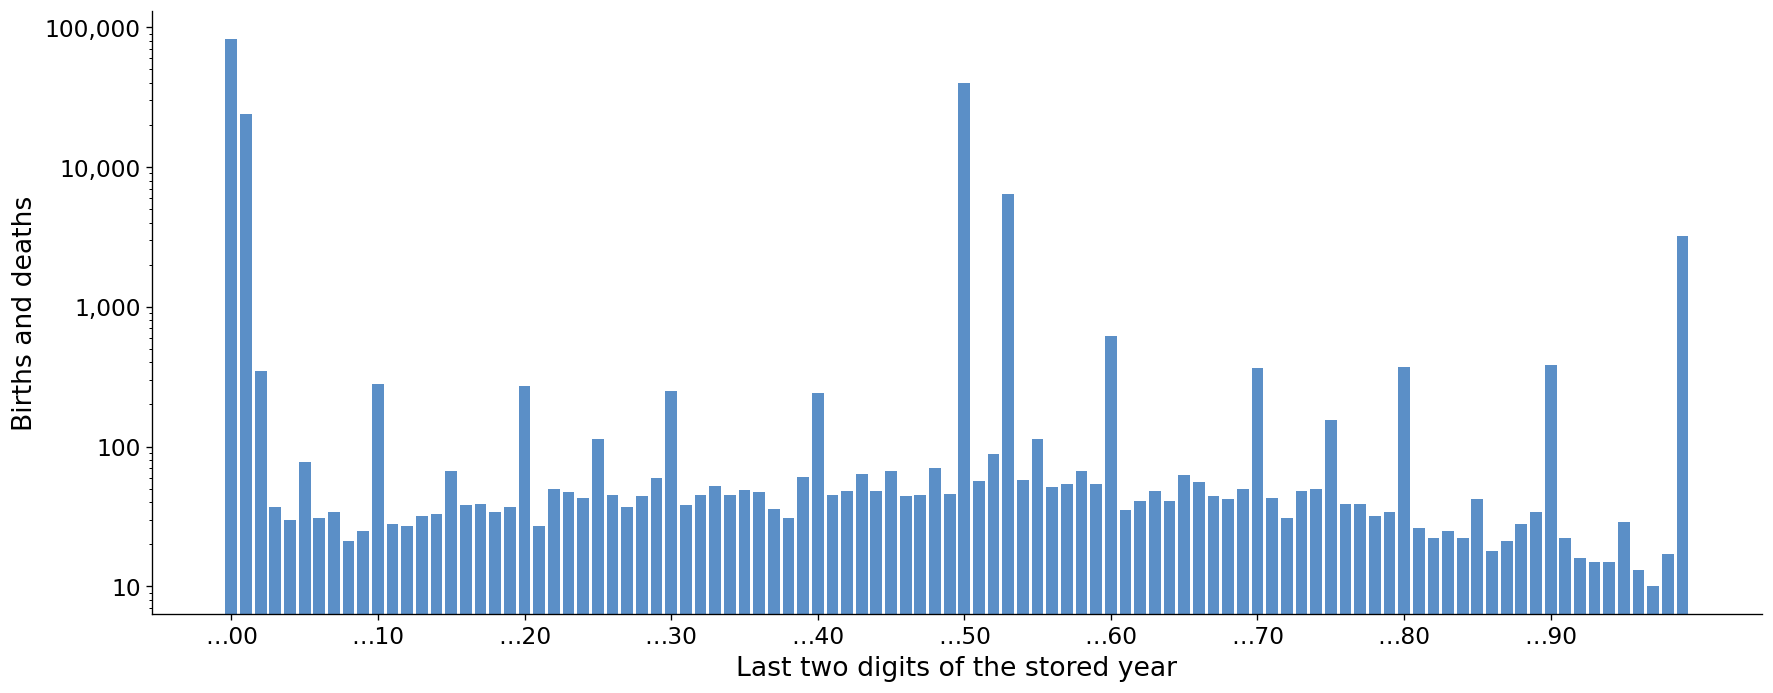

In [9]:
centuries = coarse_years.filter(pl.col('precision') == 'century', pl.col('date') != 'work inception').with_columns((pl.col('year').abs() % CENTURY).alias('rest'))
counts = centuries.group_by('rest').len().sort('rest')
fig, ax = plt.subplots(figsize=FIGSIZE_WIDE)
ax.bar(counts['rest'], counts['len'], width=0.8, color=MAIN_COLOR)
ax.set_yscale('log')
ax.yaxis.set_major_formatter(THOUSANDS)
ax.set_xticks(range(0, CENTURY, 10))
ax.set_xticklabels([f'…{rest:02d}' for rest in range(0, CENTURY, 10)])
ax.set_xlabel('Last two digits of the stored year')
ax.set_ylabel('Births and deaths')
ax.grid(axis='x', visible=False)
plt.tight_layout()
plt.show()

### Most frequent coarse years that are not round

In [10]:
coarse_years.filter(pl.col('position') == 'other year').group_by('date', 'precision', 'year').len().sort('len', descending=True).head(TOP_YEARS)

date,precision,year,len
str,str,i64,u32
"""birth""","""century""",1953,6425
"""death""","""century""",1999,1409
"""work inception""","""century""",1651,537
"""work inception""","""millennium""",1908,527
"""work inception""","""century""",1655,494
"""work inception""","""century""",1657,476
"""work inception""","""century""",1662,470
"""work inception""","""century""",1939,458
"""work inception""","""century""",1637,452


## Which century does the stored year mean?
Individuals with a coarse birth and a precise death (or the reverse) tell where the true date lies. The true birth is guessed as the death minus the median age at death of the century, the true death as the birth plus it. The **shift** is the stored year minus that guess:

- about **+50**: the stored year is the end of the century (1600 = 1501–1600, Wikidata's convention),
- about **0**: the middle,
- about **−50**: the start (1600 = 1600–1699).

In [11]:
lives = (
    people.filter(pl.col('birth_year').is_not_null() & pl.col('death_year').is_not_null() & (pl.col('birth_year') <= LAST_BIRTH_YEAR))
    .with_columns((pl.col('death_year') - pl.col('birth_year')).alias('age_at_death'))
    .filter(pl.col('age_at_death').is_between(*AGE_RANGE))
)
global_age = lives['age_at_death'].median()
ages = (
    lives.group_by((pl.col('birth_year') // CENTURY * CENTURY).alias('century'))
    .agg(pl.len().alias('cohort'), pl.col('age_at_death').median().alias('median_age'))
    .filter(pl.col('cohort') >= MIN_COHORT)
    .drop('cohort')
)
print(f'{lives.height:,} individuals with both dates precise, median age at death {global_age:.0f}')
ages.sort('century').tail(5)

2,415,592 individuals with both dates precise, median age at death 70


century,median_age
i64,f64
1500,61.0
1600,63.0
1700,67.0
1800,70.0
1900,77.0


In [12]:
def with_age(frame, birth):
    return (
        frame.with_columns((birth // CENTURY * CENTURY).alias('century'))
        .join(ages, on='century', how='left')
        .with_columns(pl.col('median_age').fill_null(global_age))
    )


births = with_age(
    position(people.filter(coarse_birth & (people['death'] == 'precise'), pl.col('coarse_birth_precision') == 'century'), 'coarse_birth_year', 'coarse_birth_precision'),
    pl.col('coarse_birth_year'),
).with_columns((pl.col('coarse_birth_year') - (pl.col('death_year') - pl.col('median_age'))).alias('shift'))
deaths = with_age(
    position(people.filter(coarse_death & (people['birth'] == 'precise'), pl.col('coarse_death_precision') == 'century'), 'coarse_death_year', 'coarse_death_precision'),
    pl.col('birth_year'),
).with_columns((pl.col('coarse_death_year') - (pl.col('birth_year') + pl.col('median_age'))).alias('shift'))
shifts = pl.concat([
    births.select(pl.lit('coarse birth, precise death').alias('individuals'), 'position', 'shift'),
    deaths.select(pl.lit('coarse death, precise birth').alias('individuals'), 'position', 'shift'),
])
print(f'{births.height:,} coarse births with a precise death, {deaths.height:,} coarse deaths with a precise birth')
shifts.sample(5, seed=SEED)

30,943 coarse births with a precise death, 9,426 coarse deaths with a precise birth


individuals,position,shift
str,str,f64
"""coarse death, precise birth""","""…00""",39.0
"""coarse birth, precise death""","""…00""",-57.0
"""coarse death, precise birth""","""…00""",8.0
"""coarse birth, precise death""","""…50""",-23.0
"""coarse death, precise birth""","""…00""",17.0


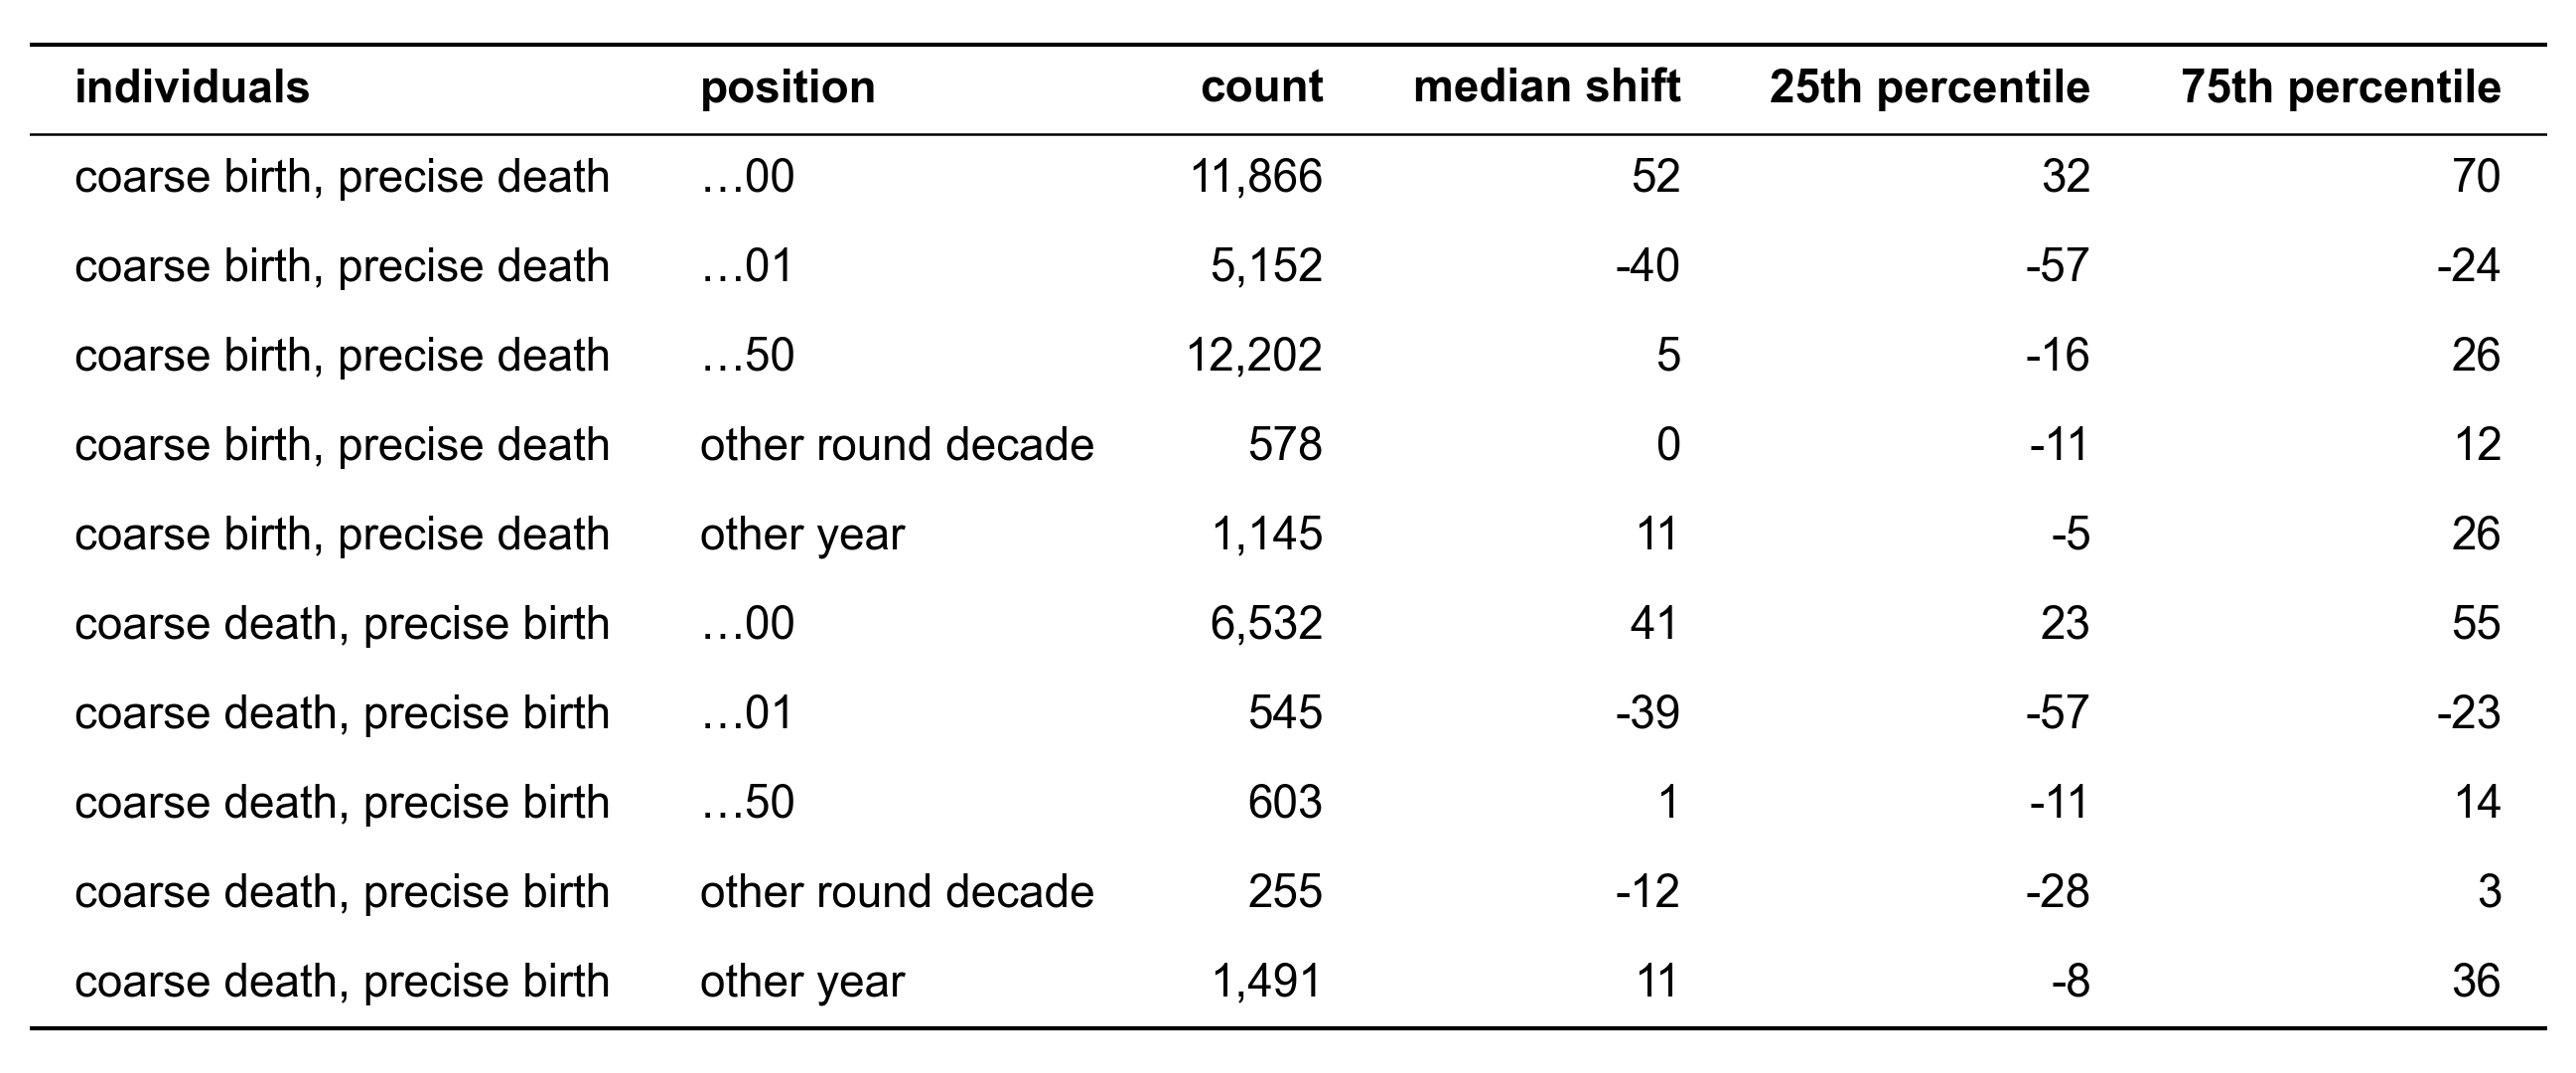

In [13]:
show_table(
    shifts.group_by('individuals', 'position')
    .agg(
        pl.len().alias('count'),
        pl.col('shift').median().alias('median shift'),
        pl.col('shift').quantile(0.25).alias('25th percentile'),
        pl.col('shift').quantile(0.75).alias('75th percentile'),
    )
    .sort('individuals', pl.col('position').replace_strict({p: i for i, p in enumerate(POSITIONS)}))
    .with_columns(pl.col('count').map_elements(lambda n: f'{n:,}', return_dtype=pl.String)),
    decimals=0,
)

### Figure 2: Shift of century-precision births, by position of the stored year

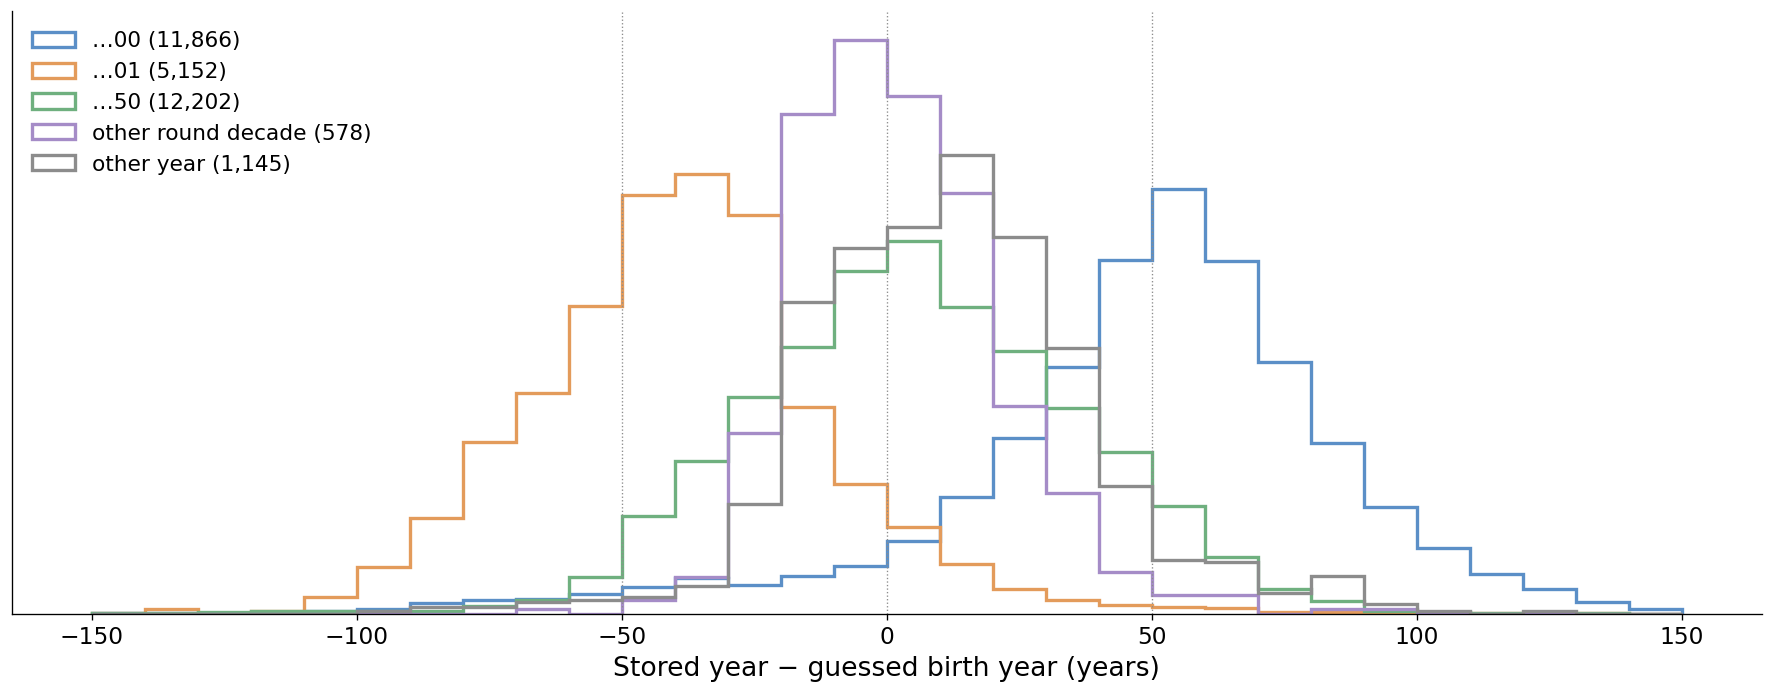

In [14]:
fig, ax = plt.subplots(figsize=FIGSIZE_WIDE)
for name, color in POSITION_COLORS.items():
    values = births.filter(pl.col('position') == name)['shift'].to_numpy()
    if len(values) >= MIN_COHORT:
        ax.hist(values, bins=SHIFT_BINS, density=True, histtype='step', linewidth=2, color=color, label=f'{name} ({len(values):,})')
for x in (-50, 0, 50):
    ax.axvline(x, **REFERENCE_LINE)
ax.set_xlabel('Stored year − guessed birth year (years)')
ax.set_yticks([])
ax.grid(axis='x', visible=False)
ax.legend(loc='upper left')
plt.tight_layout()
plt.show()